In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import copy

import scipy.stats as stats
import re

import os
%config InlineBackend.figure_format ='retina'

%load_ext autoreload
%autoreload 2

import sys
sys.path.insert(0, "../../")
import builtins
    
builtins.NAMING = "new"

from RealTrace_paper_analysis.plotting_src.read_ggp_run import * # you might need to change these two line, such that you can use read ggp_run
from RealTrace_paper_analysis.simulations.cells_simulation import * # you might need to change these two line, such that you can use read ggp_run

from RealTrace_paper_analysis.plotting_src.cells_utils import *
from RealTrace_paper_analysis.plotting_src.read_utils import *
from RealTrace_paper_analysis.plotting_src.header_settings import *

from RealTrace_paper_analysis.plotting_src.naive_rates import *

from mpl_toolkits.axes_grid1.inset_locator import (inset_axes, InsetPosition,
                                                  mark_inset)
import matplotlib
%config InlineBackend.figure_format ='retina'


header_setting.py: using new naming


In [2]:
color_by_condition_Kennard = {'Glc': "tab:olive",
                            'CAA': "tab:green",
                            'RDM': "tab:blue"}
prediction_files = get_suffix_files("../../ecoli_other_labs/Kennard2016/RealTrace_out/", suffix='prediction.csv') 
prediction_files

['../../ecoli_other_labs/Kennard2016/RealTrace_out/Data_CAA_P5ori_processed_f8_b0123457_prediction.csv',
 '../../ecoli_other_labs/Kennard2016/RealTrace_out/Data_Glc_P5ori_processed_f8_b0123457_prediction.csv',
 '../../ecoli_other_labs/Kennard2016/RealTrace_out/Data_RDM_P5ori_processed_f8_b0123457_prediction.csv']

../../ecoli_other_labs/Kennard2016/RealTrace_out/Data_CAA_P5ori_processed_f8_b0123457_prediction.csv


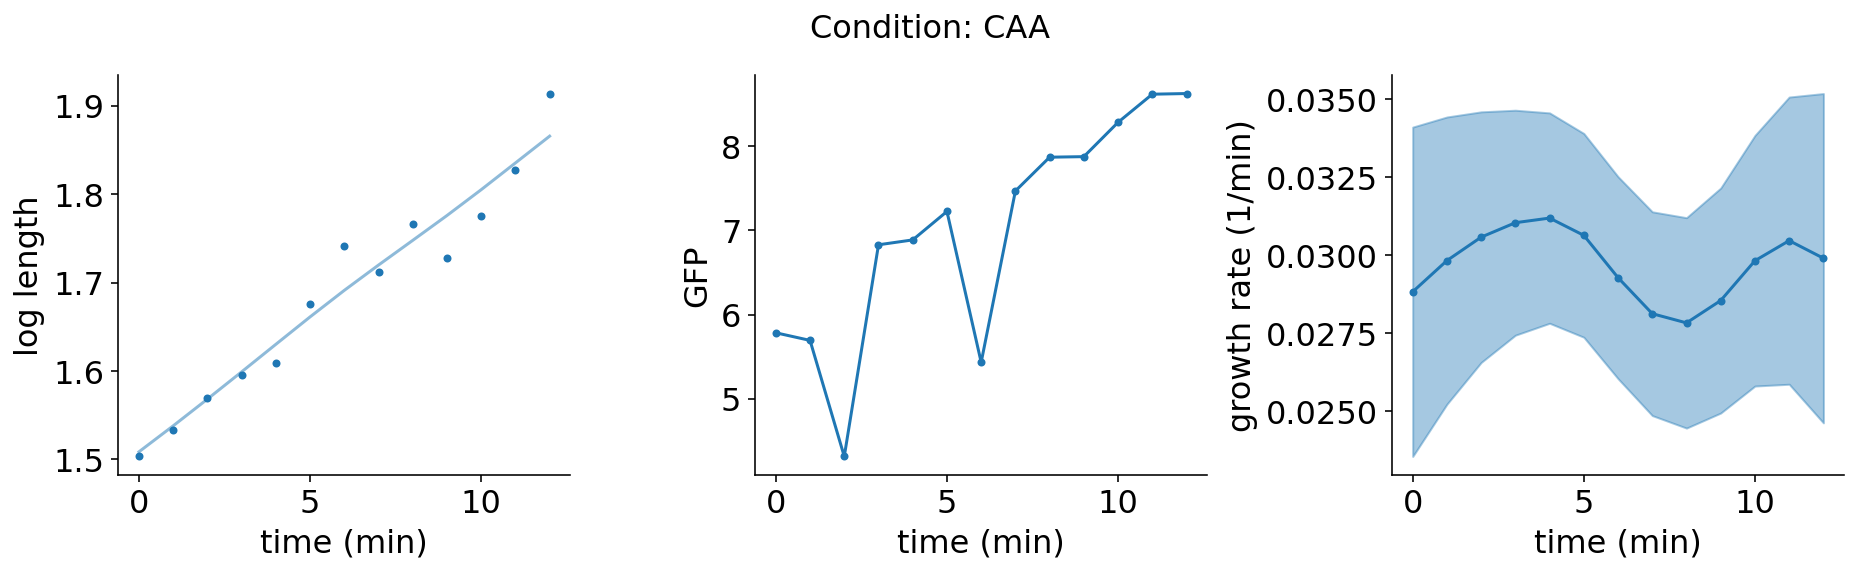

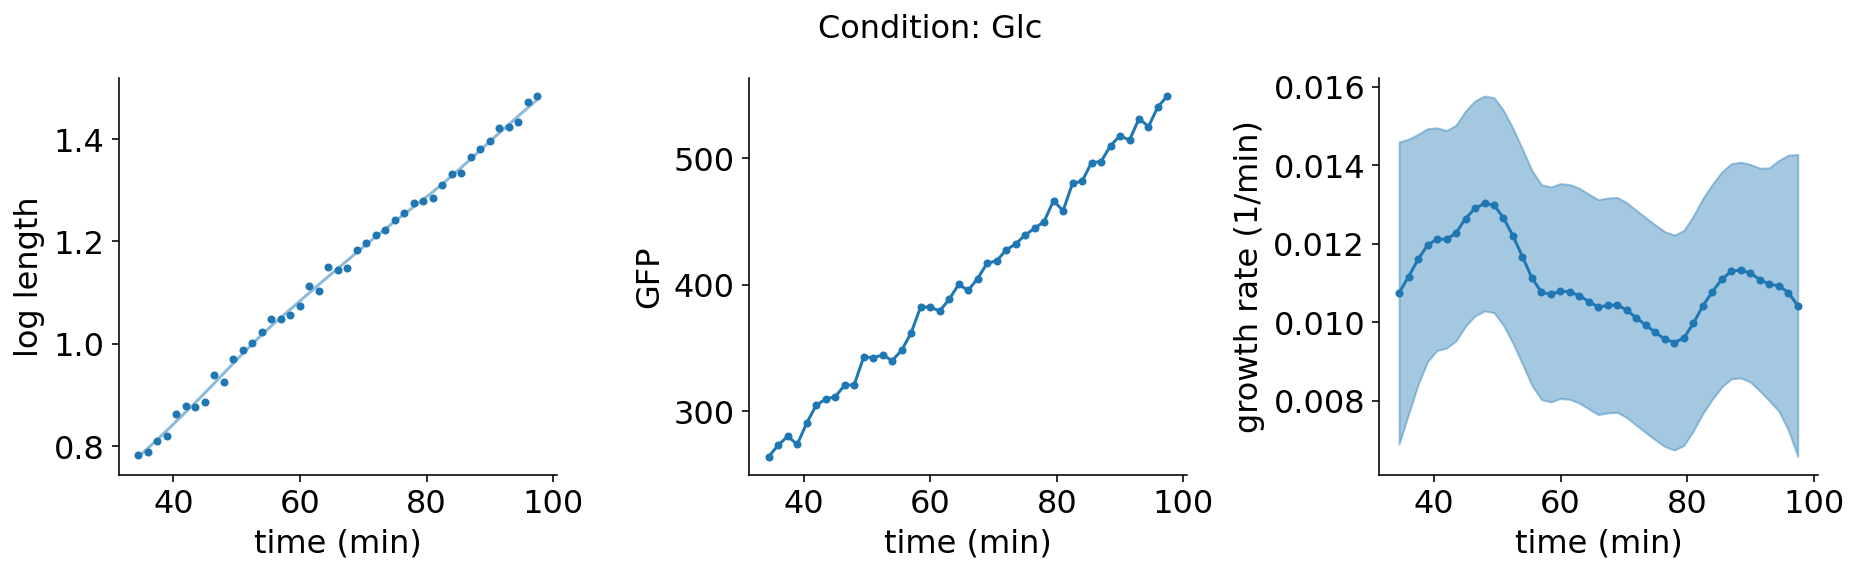

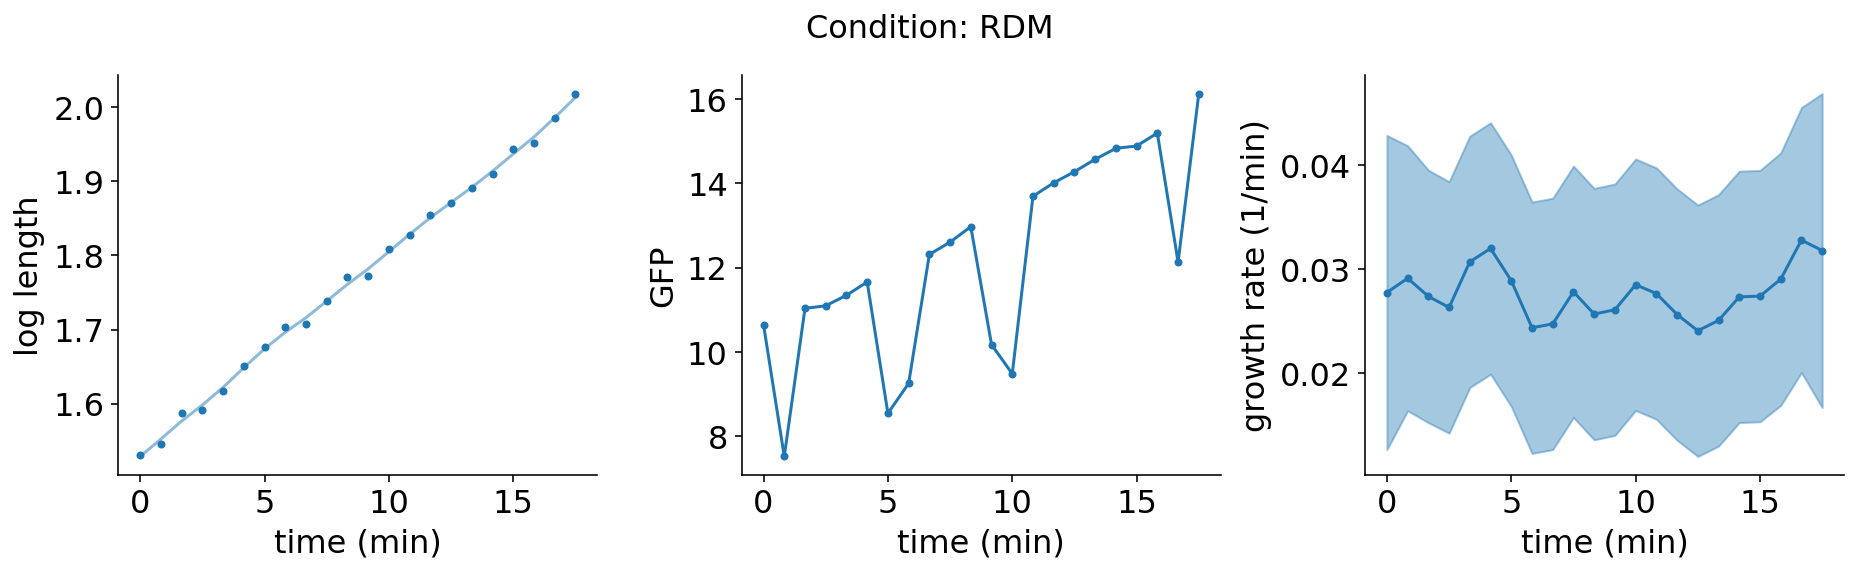

In [16]:
def lin_func(x, m, b):
    return m*x+b

def fit_lin(x, y):
    popt, pcov = curve_fit(lin_func, x, y)
    return popt
    
def flatten_log_length(t, x):
    m, b = fit_lin(t, x)
    pred = lin_func(t, m, b)
    return x-pred
 
    
def plot_raw(filename):
    fig, ax = plt.subplots(1,3, figsize=(FULL_SIZE,FULL_HEIGHT))
    
    for a in ax:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)

        a.spines['right'].set_color('none')
        a.yaxis.tick_left()

        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()
        
    data = pd.read_csv(filename, skiprows=header_lines(filename))
    cells_data = df2ggp_cells(data)

    cond = filename.split("/")[-1].split("_")[1]
    fig.suptitle("Condition: "+cond)
    ax[0].set_xlabel("time (min)")
    ax[1].set_xlabel("time (min)")
    ax[2].set_xlabel("time (min)")


    ax[0].set_ylabel("log length")
    ax[1].set_ylabel("GFP")
    ax[2].set_ylabel("growth rate (1/min)")

    for i, cell in enumerate(cells_data[1:2]):
        c = colors[i]
        # f_ll = flatten_log_length(cell.time, cell.log_length)

        
        
        ax[0].scatter(cell.time, cell.log_length, marker=".", color=c)
        ax[0].plot(cell.time, cell.mean_x, alpha=0.5, color=c)
        # ax[0].plot([cell.time[0], cell.time[-1]], [cell.log_length[0], cell.log_length[-1]],
                                                   # marker=".", color="grey")
        
        ax[1].plot(cell.time, cell.gfp/1e3, marker=".", color=c)
        
        ax[2].plot(cell.time, cell.mean_l, marker=".", color=c)
        ax[2].fill_between(cell.time, cell.mean_l+np.sqrt(cell.cov_ll),
                           cell.mean_l-np.sqrt(cell.cov_ll), color=c, alpha=0.4)
    plt.tight_layout()
print(prediction_files[0])
plot_raw(prediction_files[0])
prediction_files[1]
plot_raw(prediction_files[1])
plot_raw(prediction_files[2])

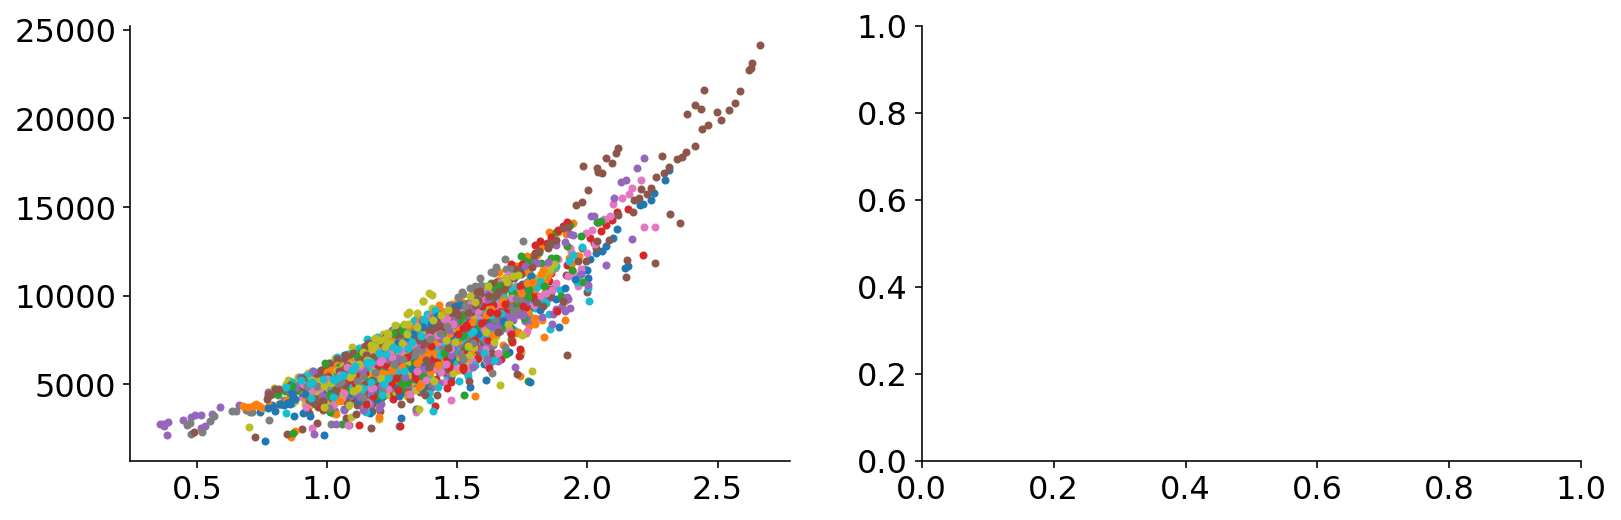

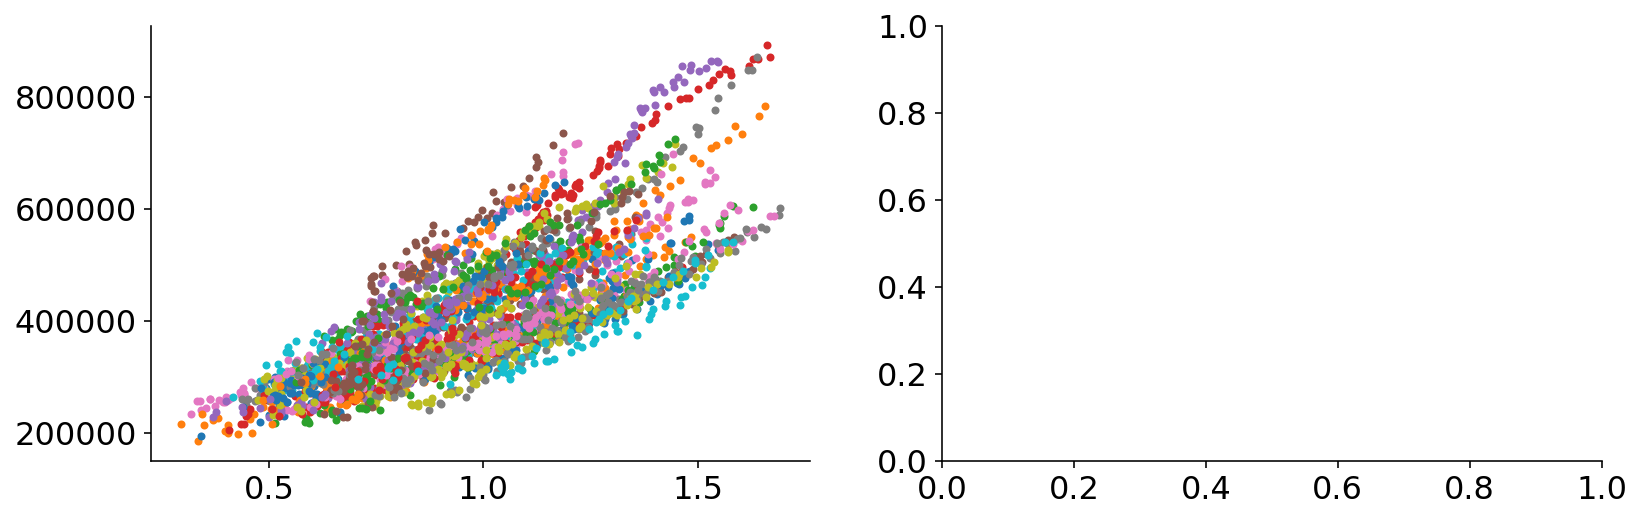

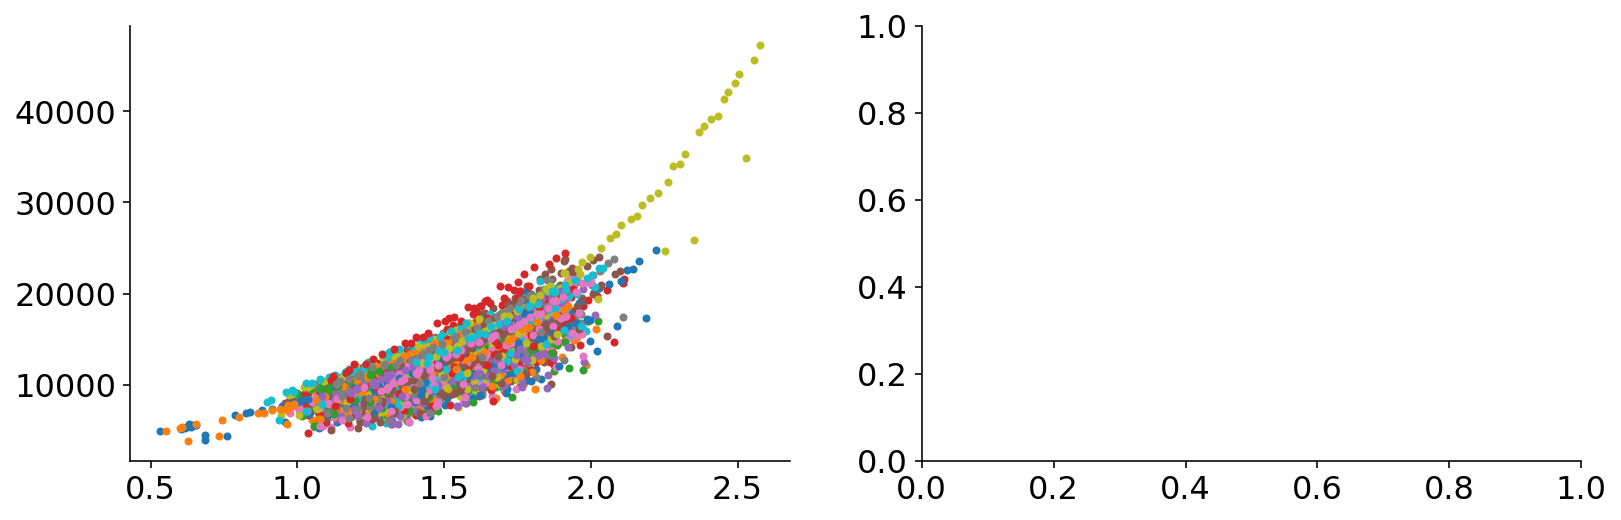

In [39]:
def lin_func(x, m, b):
    return m*x+b

def fit_lin(x, y):
    popt, pcov = curve_fit(lin_func, x, y)
    return popt
    
def flatten_log_length(t, x):
    m, b = fit_lin(t, x)
    pred = lin_func(t, m, b)
    return x-pred
 
    
def plot_raw(filename):
    fig, ax = plt.subplots(1,2, figsize=(FULL_SIZE,FULL_HEIGHT))
    
    for a in ax:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)

        a.spines['right'].set_color('none')
        a.yaxis.tick_left()

        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()
        
    data = pd.read_csv(filename, skiprows=header_lines(filename))
    cells_data = df2ggp_cells(data)

    for cell in cells_data[:100]:
        # f_ll = flatten_log_length(cell.time, cell.log_length)
        
        ax[0].scatter(cell.log_length, cell.gfp, marker=".")
    
plot_raw(prediction_files[0])
plot_raw(prediction_files[1])
plot_raw(prediction_files[2])

../../ecoli_other_labs/Kennard2016/RealTrace_out/Data_CAA_P5ori_processed_f8_b0123457_prediction.csv


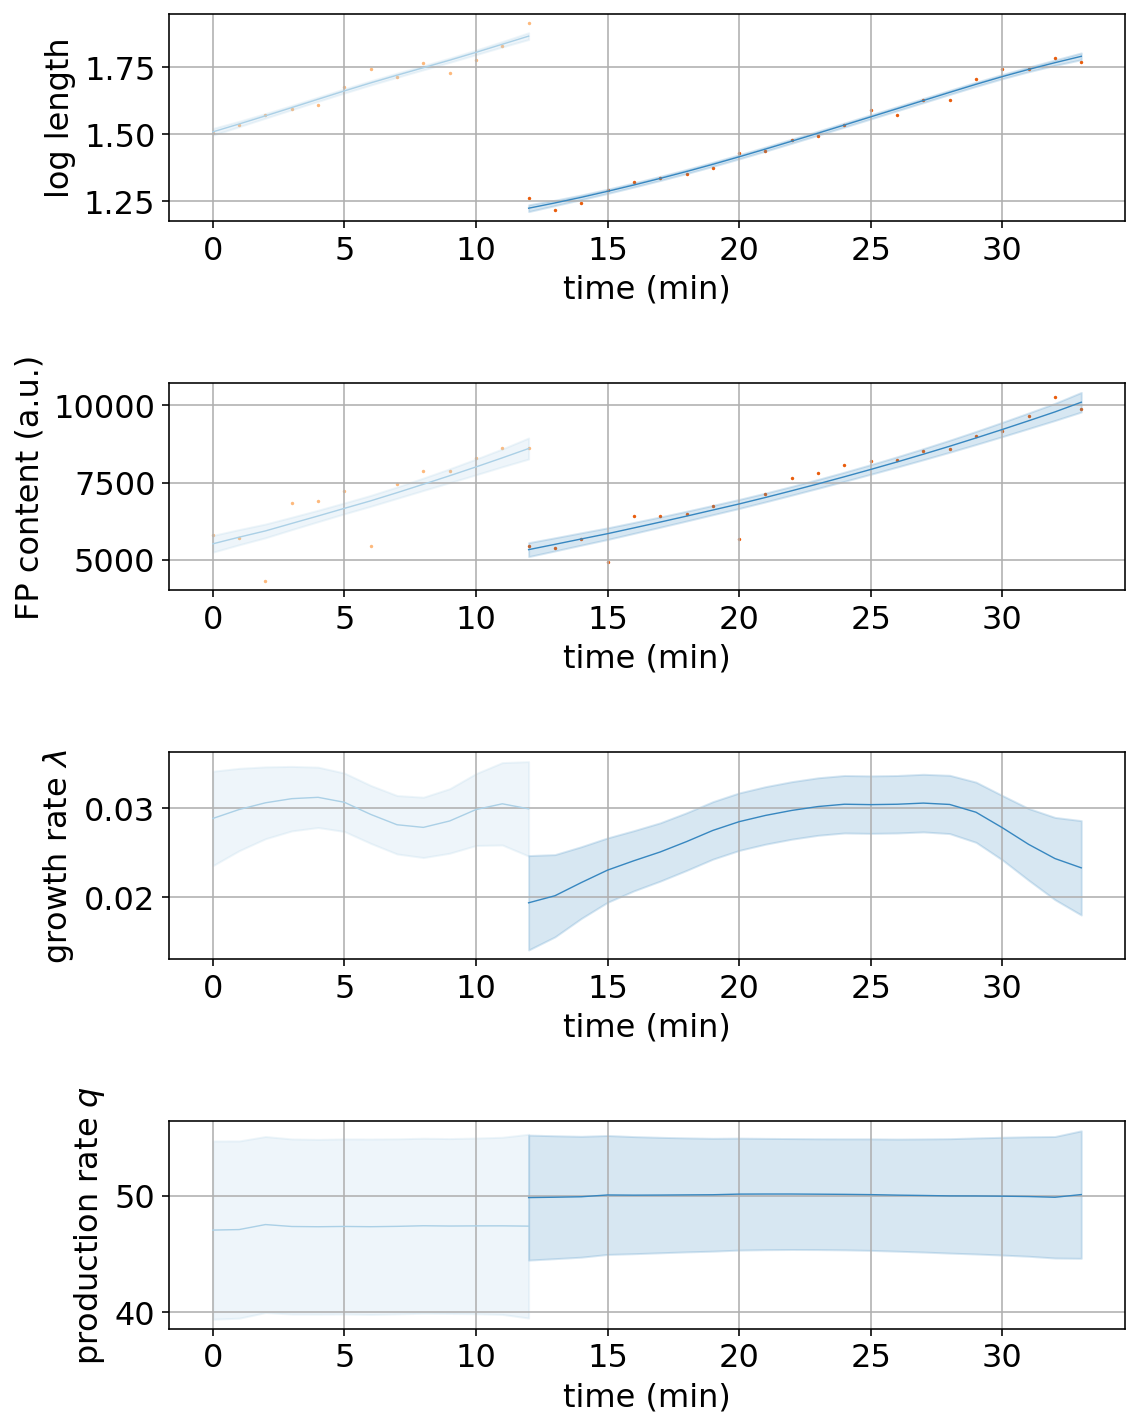

../../ecoli_other_labs/Kennard2016/RealTrace_out/Data_Glc_P5ori_processed_f8_b0123457_prediction.csv


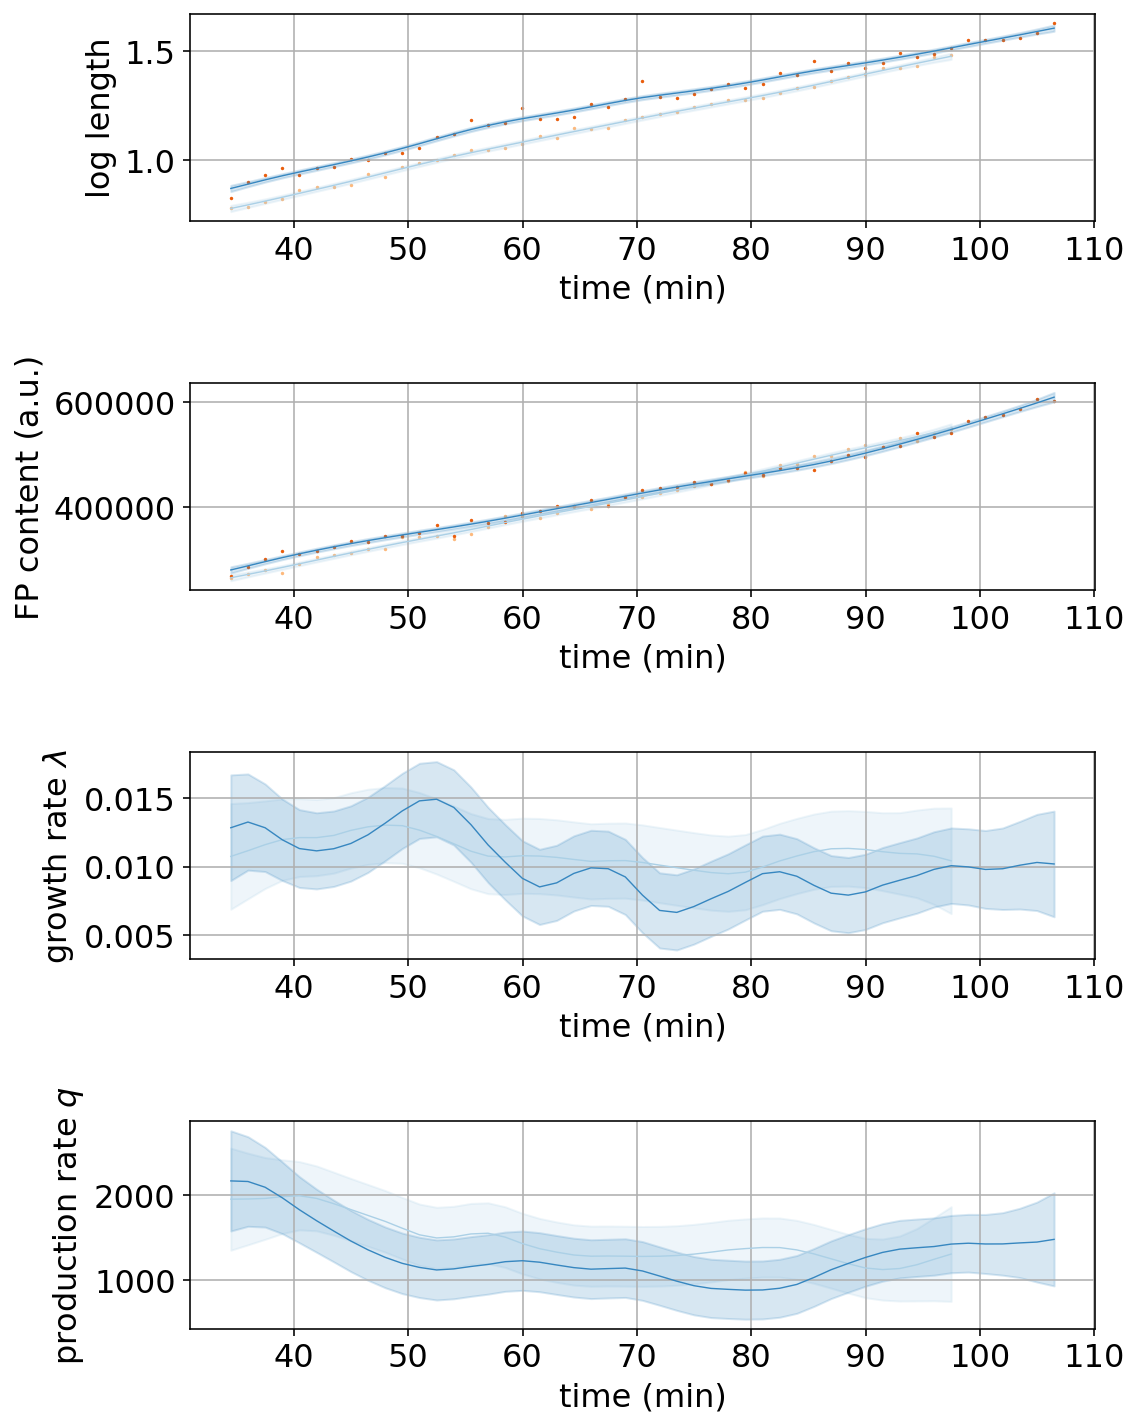

../../ecoli_other_labs/Kennard2016/RealTrace_out/Data_RDM_P5ori_processed_f8_b0123457_prediction.csv


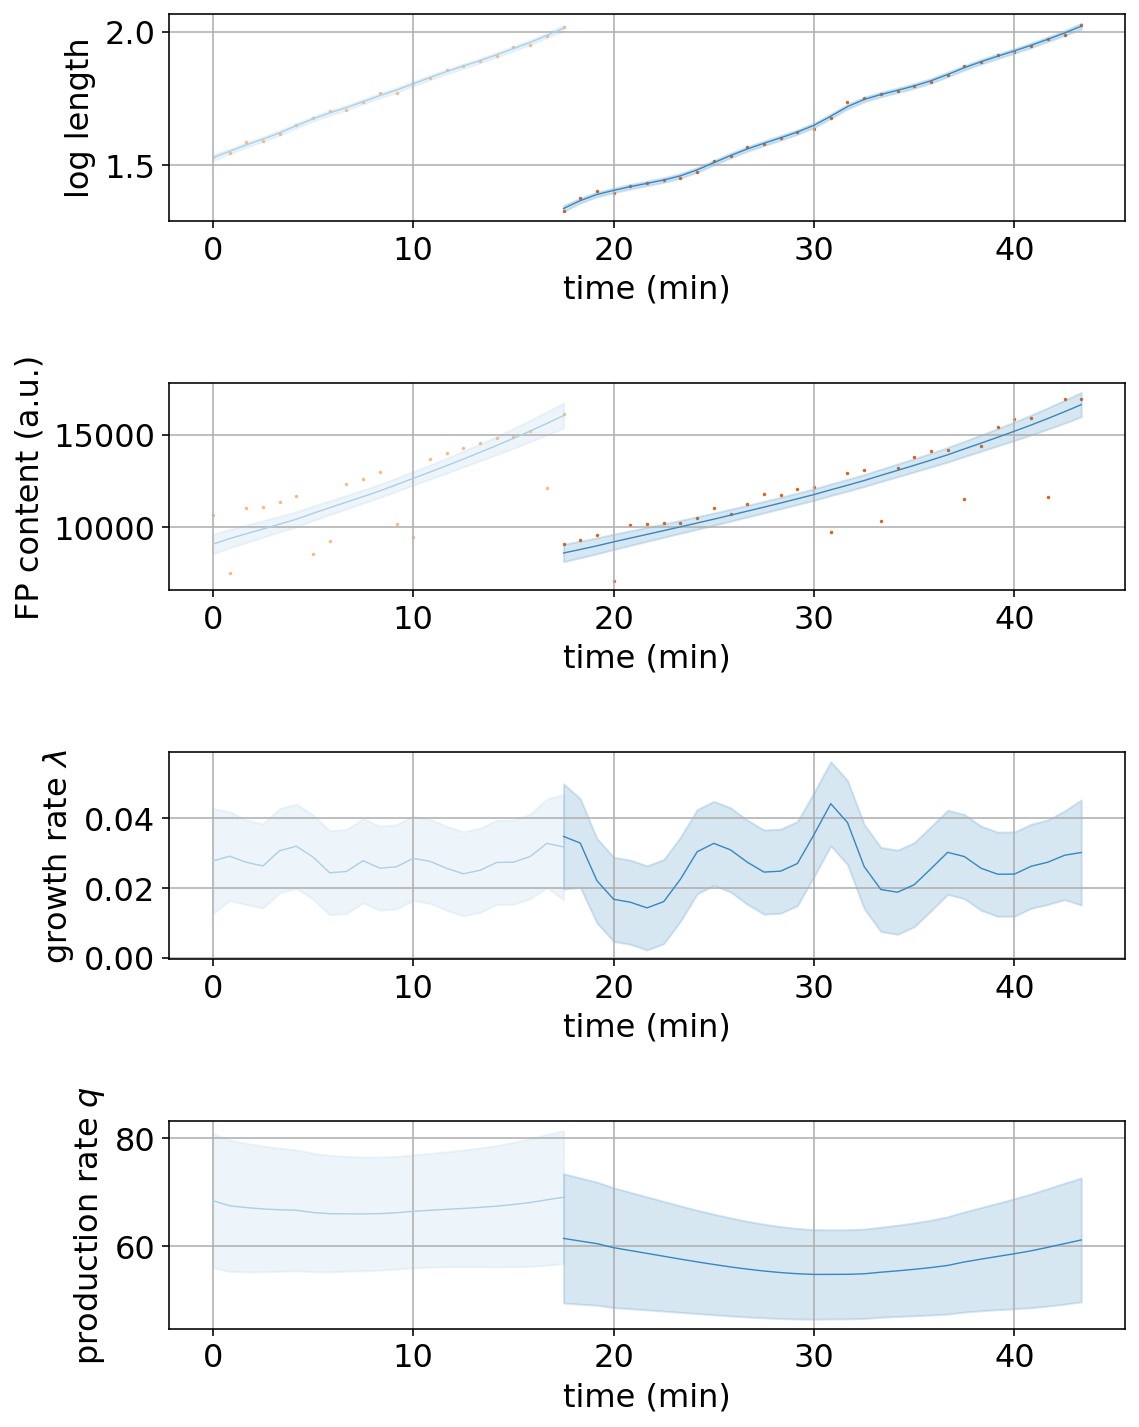

In [5]:
for i in range(3):
    print(prediction_files[i])
    _=  plot_predictions(prediction_files[i],
                        start=1, stop=3, step=1, 
                        time_unit=('min', 1), 
                        show=True)